In [31]:
from pathlib import Path

import librosa
import pandas as pd

from audioml.shared import root_mean_square, spectral_centroid, zero_crossing_rate
from tqdm.notebook import tqdm
from sklearn.model_selection import train_test_split
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt
import numpy as np

tqdm.pandas()

In [32]:
prefix = Path("../data/")

with open(prefix.joinpath("labels.csv"), "r") as f:
    labels: pd.DataFrame = pd.read_csv(f)

In [33]:
labels.source_file = labels.source_file.progress_apply(lambda x: prefix.joinpath(Path("raw", *Path(x).parts[2:])))
labels.processed_file = labels.processed_file.progress_apply(
    lambda x: prefix.joinpath(Path("processed", *Path(x).parts[1:])))

  0%|          | 0/5940 [00:00<?, ?it/s]

  0%|          | 0/5940 [00:00<?, ?it/s]

In [34]:
labels

,source_file,processed_file,fire_seeker_gain,fire_seeker_low,fire_seeker_mid,fire_seeker_treble
0,data/raw/Gretsch/Gretsch_F_open_122_ID1_4.wav,data/processed/Gretsch/Gretsch_F_open_122_ID1_...,0.415212,0.382531,0.889004,0.717846
1,data/raw/Gretsch/Gretsch_F_open_122_ID1_4.wav,data/processed/Gretsch/Gretsch_F_open_122_ID1_...,0.828639,0.576327,0.966072,0.016324
2,data/raw/Gretsch/Gretsch_F_open_122_ID1_4.wav,data/processed/Gretsch/Gretsch_F_open_122_ID1_...,0.093933,0.267912,0.440884,0.377729
3,data/raw/Gretsch/Gretsch_Am_open_222_ID1_10.wav,data/processed/Gretsch/Gretsch_Am_open_222_ID1...,0.431810,0.530798,0.718583,0.089766
4,data/raw/Gretsch/Gretsch_Am_open_222_ID1_10.wav,data/processed/Gretsch/Gretsch_Am_open_222_ID1...,0.753418,0.978355,0.633111,0.856575
...,...,...,...,...,...,...
5935,data/raw/ArgSG/ArgSG_Cm_open_022_ID1_5.wav,data/processed/ArgSG/ArgSG_Cm_open_022_ID1_5_2...,0.887720,0.522724,0.678754,0.832677
5936,data/raw/ArgSG/ArgSG_Cm_open_022_ID1_5.wav,data/processed/ArgSG/ArgSG_Cm_open_022_ID1_5_3...,0.169129,0.621126,0.746800,0.012066
5937,data/raw/ArgSG/ArgSG_C_open_12020_ID4_9.wav,data/processed/ArgSG/ArgSG_C_open_12020_ID4_9_...,0.086258,0.865983,0.808389,0.093712
5938,data/raw/ArgSG/ArgSG_C_open_12020_ID4_9.wav,data/processed/ArgSG/ArgSG_C_open_12020_ID4_9_...,0.148841,0.356804,0.639141,0.270942


In [35]:
def filter_existing(row: pd.Series) -> bool:
    return row.processed_file.exists()

In [36]:
def calculate_features(row: pd.Series) -> pd.Series:
    x, sr = librosa.load(row.processed_file)
    row["root_mean_square"] = root_mean_square(x)
    row["spectral_centroid"] = spectral_centroid(x, sr=sr)
    row["zero_crossing_rate"] = zero_crossing_rate(x)
    return row

In [37]:
Path("../data/processed/ArgSG/ArgSG_E_open_12020_ID4_5_2.wav").exists()

True

In [38]:
tqdm.pandas(desc="Filtering")
filtered = labels[labels.progress_apply(filter_existing, axis=1)]  # todo: remove when i have full dataset
tqdm.pandas(desc="Calculating Features")
features = filtered.progress_apply(calculate_features, axis=1)

Filtering:   0%|          | 0/5940 [00:00<?, ?it/s]

Calculating Features:   0%|          | 0/23 [00:00<?, ?it/s]

In [39]:
features

,source_file,processed_file,fire_seeker_gain,fire_seeker_low,fire_seeker_mid,fire_seeker_treble,root_mean_square,spectral_centroid,zero_crossing_rate
5917,data/raw/ArgSG/ArgSG_Bm_open_022_ID1_4.wav,data/processed/ArgSG/ArgSG_Bm_open_022_ID1_4_2...,0.370308,0.117698,0.216662,0.439914,0.004232,1097.442109,0.040584
5918,data/raw/ArgSG/ArgSG_Bm_open_022_ID1_4.wav,data/processed/ArgSG/ArgSG_Bm_open_022_ID1_4_3...,0.546825,0.731447,0.297915,0.192404,0.007889,975.047951,0.033290
5919,data/raw/ArgSG/ArgSG_E_open_022_ID4_2.wav,data/processed/ArgSG/ArgSG_E_open_022_ID4_2_1.wav,0.104349,0.287023,0.303175,0.728407,0.000832,1138.380914,0.047324
5920,data/raw/ArgSG/ArgSG_E_open_022_ID4_2.wav,data/processed/ArgSG/ArgSG_E_open_022_ID4_2_2.wav,0.398437,0.722418,0.289023,0.060477,0.003951,745.218039,0.032193
5921,data/raw/ArgSG/ArgSG_E_open_022_ID4_2.wav,data/processed/ArgSG/ArgSG_E_open_022_ID4_2_3.wav,0.730641,0.779052,0.295458,0.322544,0.007966,1142.867234,0.036334
5922,data/raw/ArgSG/ArgSG_D_open_222_ID4_5.wav,data/processed/ArgSG/ArgSG_D_open_222_ID4_5_1.wav,0.990732,0.200477,0.241408,0.541850,0.005118,1849.835768,0.058122
5923,data/raw/ArgSG/ArgSG_D_open_222_ID4_5.wav,data/processed/ArgSG/ArgSG_D_open_222_ID4_5_2.wav,0.299360,0.864863,0.560551,0.616967,0.001332,1378.015822,0.058260
5924,data/raw/ArgSG/ArgSG_D_open_222_ID4_5.wav,data/processed/ArgSG/ArgSG_D_open_222_ID4_5_3.wav,0.487492,0.595269,0.786569,0.331803,0.002854,1343.693890,0.052120
5925,data/raw/ArgSG/ArgSG_Gm_open_022_ID1_2.wav,data/processed/ArgSG/ArgSG_Gm_open_022_ID1_2_1...,0.756349,0.568006,0.466119,0.060982,0.011656,1170.751086,0.042417
5926,data/raw/ArgSG/ArgSG_Gm_open_022_ID1_2.wav,data/processed/ArgSG/ArgSG_Gm_open_022_ID1_2_2...,0.238263,0.214241,0.109422,0.268965,0.003315,844.357658,0.040034


In [40]:
X = features[["root_mean_square", "spectral_centroid", "zero_crossing_rate"]]
y = features[["fire_seeker_gain", "fire_seeker_low", "fire_seeker_mid"]]

In [41]:
def to_tensor(x: pd.DataFrame) -> torch.Tensor:
    return torch.tensor(x.to_numpy(), dtype=torch.float)

In [42]:
X_train_unscaled, X_rest, y_train, y_rest = map(to_tensor, train_test_split(X, y, test_size=0.2, random_state=0))
X_val_unscaled, X_test_unscaled, y_val, y_test = train_test_split(X_rest, y_rest, test_size=0.5, random_state=0)

In [43]:
display(X_train_unscaled[0:2])
display(y_train[0:2])

tensor([[7.8888e-03, 9.7505e+02, 3.3290e-02],
        [1.4127e-03, 1.0023e+03, 4.4845e-02]])

tensor([[0.5468, 0.7314, 0.2979],
        [0.3267, 0.5853, 0.6100]])

In [44]:
scaler = StandardScaler()
X_train = torch.tensor(scaler.fit_transform(X_train_unscaled), dtype=torch.float)
X_val = torch.tensor(scaler.transform(X_val_unscaled), dtype=torch.float)
X_test = torch.tensor(scaler.transform(X_test_unscaled), dtype=torch.float)

In [45]:
class Model(nn.Module):
    def __init__(self):
        super(Model, self).__init__()
        self.fc1 = nn.Linear(3, 10)
        self.fc2 = nn.Linear(10, 10)
        self.fc3 = nn.Linear(10, 10)
        self.fc4 = nn.Linear(10, 3)

    def forward(self, x):
        x = self.fc1(x)
        x = F.relu(x)

        x = self.fc2(x)
        x = F.relu(x)

        x = self.fc3(x)
        x = F.relu(x)

        x = self.fc4(x)

        return x

In [46]:
model = Model()
display(model)

criterion = nn.HuberLoss()
optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
loss_history = []

for epoch in (n := tqdm(range(5000))):
    optimizer.zero_grad()
    output = model(X_train)
    loss = criterion(output, y_train)
    loss.backward()
    optimizer.step()
    n.postfix = str(loss.item())
    loss_history.append(loss.item())

Model(
  (fc1): Linear(in_features=3, out_features=10, bias=True)
  (fc2): Linear(in_features=10, out_features=10, bias=True)
  (fc3): Linear(in_features=10, out_features=10, bias=True)
  (fc4): Linear(in_features=10, out_features=3, bias=True)
)

  0%|          | 0/5000 [00:00<?, ?it/s]

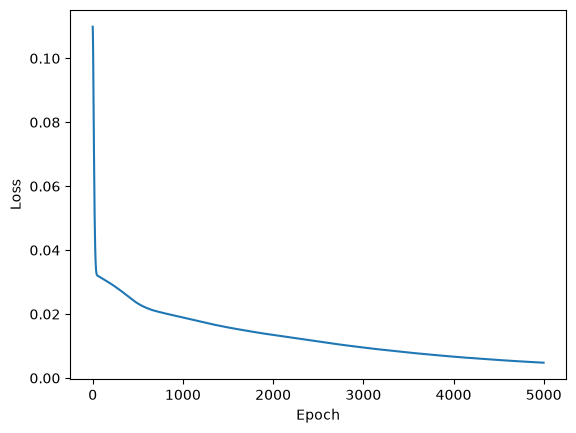

In [47]:
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.plot(loss_history)

In [48]:
a = (model(X_test[0]), y_test[0])
display(a)
criterion(*a)

(tensor([0.3386, 1.5258, 1.1182], grad_fn=<UnsafeViewBackward0>),
 tensor([0.1488, 0.3568, 0.6391]))

tensor(0.2672, grad_fn=<HuberLossBackward0>)

In [49]:
# The arguments for torch.hub.load are the github repo that hosts the model
# and the name of the model
VGGish = torch.hub.load('harritaylor/torchvggish', 'vggish')

#This just removes the output ReLU layer from the model
VGGish.postprocess = False
VGGish.embeddings = torch.nn.Sequential(*list(VGGish.embeddings.children())[:-1])
VGGish.eval()

Using cache found in /home/auri/.cache/torch/hub/harritaylor_torchvggish_master


VGGish(
  (features): Sequential(
    (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (11): Conv2d(256, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): ReLU(inplace=True)
    (13): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (14): ReLU(inplace=True)
    (15): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False

In [50]:
dummy_audio = np.random.randn(16000)
 # Call the model on the audio
dummy_feats = VGGish.forward(x=dummy_audio, fs=16000)

In [51]:
print(dummy_feats.shape)
print(dummy_feats)

torch.Size([1, 128])
tensor([[-0.7065, -0.7123, -0.2943, -1.2213, -1.1184, -2.2267,  0.0636, -0.2169,
         -1.8764, -0.9643, -0.3215, -0.6185, -1.4806, -0.2190, -0.1276,  0.4152,
          0.4319, -0.2545, -0.3753,  0.1187,  0.0540,  0.8525, -0.5739, -0.6307,
         -0.7832,  0.1269,  0.2149, -0.0061,  0.6143, -0.3413,  1.3321, -0.2940,
          0.7778, -0.3132, -0.2359,  0.1338, -0.3618, -1.2925, -0.9108, -0.3072,
          1.1418, -1.0496, -0.1091, -0.7586, -0.2851, -0.4396, -0.2954,  0.3816,
         -0.1202,  0.7766, -0.6472, -0.7963, -1.7085, -1.4738, -0.4076, -0.3397,
          0.0321,  0.0381, -0.8399, -0.4551, -0.6323, -0.9116, -1.2508, -0.7283,
         -0.1391, -0.3166, -0.2974,  0.6265, -0.5468, -0.8992, -0.9728, -0.5085,
         -1.0865, -1.5323, -0.3418,  0.5669, -1.2648, -0.0267, -0.2007, -0.2032,
         -0.0890,  0.6081, -0.9989, -1.2166, -0.7357,  0.0682,  0.5641, -0.2506,
          0.2659,  0.5470, -1.0240, -0.0902, -0.8468,  2.1417, -0.3987,  0.6944,
       